# 05 — Classification supervisée des segments CAH

## Étape 2 — Apprentissage et évaluation

**Objectif :** apprendre à reproduire les étiquettes de la CAH de référence, sans relancer l'ACM ni Ward.

**Référence figée :** 20 000 clients, 4 axes de l'ACM 3, méthode Ward, **k = 5**, graine 42. Les résultats du classifieur doivent être interprétés comme des **prédictions des étiquettes CAH**, non comme une validation indépendante de la stabilité de la segmentation.

Ce notebook ne projette pas encore de nouveaux clients à partir de leurs variables brutes : cette fonction sera vérifiée dans l'étape de déploiement.

## 1. Initialisation

In [1]:
from pathlib import Path
import sys
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

RACINE = Path.cwd().resolve()
if RACINE.name == "notebooks":
    RACINE = RACINE.parent
if str(RACINE) not in sys.path:
    sys.path.insert(0, str(RACINE))

from src.classification_supervisee import (
    NOMS_METIER_K5, charger_reference_cah, decouper_apprentissage,
    construire_modeles, evaluer_modele,
)

GRAINE_CAH = 42
NOMBRE_AXES = 4
NOMBRE_GROUPES = 5
TAILLE_REFERENCE = 20000
GRAINE_APPRENTISSAGE = 42
PROPORTION_TEST = 0.20

## 2. Chargement et contrôles stricts de la référence

In [2]:
X, y, partitions_reference, colonnes_axes, parametres_cah, metadonnees_acm = (
    charger_reference_cah(
        RACINE, taille=TAILLE_REFERENCE, axes=NOMBRE_AXES,
        graine=GRAINE_CAH, k=NOMBRE_GROUPES,
    )
)
assert len(X) == len(y) == TAILLE_REFERENCE
assert metadonnees_acm["iteration"] == 3
assert len(metadonnees_acm["variables_actives"]) == 10
assert len(metadonnees_acm["modalites_actives"]) == 42
print("Coordonnées utilisées :", colonnes_axes)
print("Effectifs par groupe CAH :")
display(y.value_counts().sort_index().rename_axis("Groupe").to_frame("Effectif"))
display(X.head())

Coordonnées utilisées : ['0', '1', '2', '3']
Effectifs par groupe CAH :


,Effectif
Groupe,
1,5134
2,4152
3,2201
4,4060
5,4453


,0,1,2,3
0,0.077413,0.247373,-0.279936,-0.148343
1,-0.247595,-0.434417,-0.189213,-0.034675
2,-0.213813,-0.546197,1.127421,0.302242
3,-0.278309,-0.303498,-0.225810,-0.213104
4,-0.211389,0.281085,-0.200891,0.582984


## 3. Séparation apprentissage / validation / test

Trois ensembles disjoints sont utilisés : **60 % pour l'apprentissage, 20 % pour la validation et 20 % pour le test final**. La validation sert à choisir le modèle ; le test reste indépendant de cette sélection. Les séparations sont stratifiées.

In [3]:
indices_developpement, indices_test = decouper_apprentissage(
    X, y, proportion_test=0.20, graine=GRAINE_APPRENTISSAGE
)
# 25 % de 80 % = 20 % du total pour la validation.
indices_apprentissage_locaux, indices_validation_locaux = decouper_apprentissage(
    X.iloc[indices_developpement].reset_index(drop=True),
    y.iloc[indices_developpement].reset_index(drop=True),
    proportion_test=0.25, graine=GRAINE_APPRENTISSAGE + 1,
)
indices_apprentissage = indices_developpement[indices_apprentissage_locaux]
indices_validation = indices_developpement[indices_validation_locaux]

X_apprentissage, y_apprentissage = X.iloc[indices_apprentissage], y.iloc[indices_apprentissage]
X_validation, y_validation = X.iloc[indices_validation], y.iloc[indices_validation]
X_test, y_test = X.iloc[indices_test], y.iloc[indices_test]
assert not (set(indices_apprentissage) & set(indices_validation))
assert not (set(indices_apprentissage) & set(indices_test))
assert not (set(indices_validation) & set(indices_test))
print(f"Apprentissage : {len(X_apprentissage):,} individus")
print(f"Validation : {len(X_validation):,} individus")
print(f"Test final : {len(X_test):,} individus")
display(pd.DataFrame({
    "Jeu": ["Apprentissage", "Validation", "Test final"],
    "Effectif": [len(X_apprentissage), len(X_validation), len(X_test)]
}))

Apprentissage : 12,000 individus
Validation : 4,000 individus
Test final : 4,000 individus


,Jeu,Effectif
0,Apprentissage,12000
1,Validation,4000
2,Test final,4000


## 4. Entraînement et validation de la régression logistique multinomiale

La **régression logistique multinomiale** est le modèle retenu pour cette étape, conformément à l'approche méthodologique discutée avec l'enseignante. Elle est entraînée sur les **quatre coordonnées factorielles** de l'ACM 3 afin de reproduire les cinq groupes de la CAH de référence.

La fonction `construire_modeles()` ne renvoie actuellement que ce modèle : la forêt aléatoire est désactivée dans `src/classification_supervisee.py`. Le tableau ci-dessous présente donc la **validation du modèle retenu**, et non une comparaison de plusieurs algorithmes lors de cette exécution. Le critère F1 macro reste utilisé pour la présentation et la sélection automatique dans le code.

In [4]:
modeles = construire_modeles(GRAINE_APPRENTISSAGE)
resultats_validation = []
for nom, modele in modeles.items():
    modele.fit(X_apprentissage, y_apprentissage)
    bilan, _, _, _ = evaluer_modele(nom, modele, X_validation, y_validation)
    resultats_validation.append(bilan)
comparaison = pd.DataFrame(resultats_validation).sort_values(
    ["f1_macro", "accuracy"], ascending=False
)
print("Performances de validation (sélection du modèle) :")
display(comparaison.round(4))

Performances de validation (sélection du modèle) :


,modele,accuracy,f1_macro,f1_pondere
0,regression_logistique_multinomiale,0.9565,0.9583,0.9564


## 5. Évaluation de la régression logistique multinomiale sur le test final

Puisque la régression logistique multinomiale est l'unique modèle actif dans `construire_modeles()`, elle est sélectionnée après la validation et réentraînée sur **apprentissage + validation (80 %)**. Les **4 000 clients du test final (20 %)** restent exclus de cet ajustement.

La matrice de confusion et les indicateurs par groupe permettent d'apprécier la fidélité aux étiquettes CAH, en particulier pour les groupes G2 et G4. Cette évaluation mesure la reproduction d'une **partition de référence déjà construite**, et non une validation indépendante de toute la chaîne ACM–CAH.

Modèle retenu (validation) : regression_logistique_multinomiale
Évaluation sur le test final réservé :


,modele,accuracy,f1_macro,f1_pondere
0,regression_logistique_multinomiale,0.9505,0.9533,0.9504


,groupe,precision,rappel,f1,effectif_test
0,1,0.951,0.971,0.961,1027
1,2,0.959,0.939,0.949,830
2,3,0.993,0.984,0.989,440
3,4,0.920,0.905,0.912,812
4,5,0.948,0.963,0.955,891


,Prédit G1,Prédit G2,Prédit G3,Prédit G4,Prédit G5
Réel G1,997,2,0,22,6
Réel G2,13,779,0,14,24
Réel G3,0,0,433,0,7
Réel G4,38,29,0,735,10
Réel G5,0,2,3,28,858


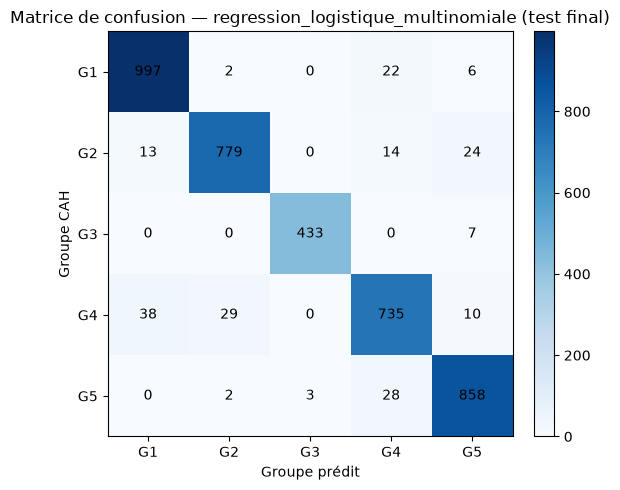

In [5]:
NOM_MODELE_RETENU = str(comparaison.iloc[0]["modele"])
modele_evalue = construire_modeles(GRAINE_APPRENTISSAGE)[NOM_MODELE_RETENU]
modele_evalue.fit(X.iloc[indices_developpement], y.iloc[indices_developpement])
bilan_test, matrice_test, rapport_test, predictions_test = evaluer_modele(
    NOM_MODELE_RETENU, modele_evalue, X_test, y_test
)
print("Modèle retenu (validation) :", NOM_MODELE_RETENU)
print("Évaluation sur le test final réservé :")
display(pd.DataFrame([bilan_test]).round(4))
display(rapport_test.round(3))
display(matrice_test)

fig, ax = plt.subplots(figsize=(6, 5))
image = ax.imshow(matrice_test.to_numpy(), cmap="Blues")
ax.set_xticks(range(5), [f"G{i}" for i in range(1, 6)])
ax.set_yticks(range(5), [f"G{i}" for i in range(1, 6)])
ax.set_xlabel("Groupe prédit")
ax.set_ylabel("Groupe CAH")
ax.set_title(f"Matrice de confusion — {NOM_MODELE_RETENU} (test final)")
for i in range(5):
    for j in range(5):
        ax.text(j, i, str(matrice_test.iat[i, j]), ha="center", va="center")
fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

## 6. Interprétation des résultats

Sur le **test final de 4 000 clients**, la régression logistique multinomiale atteint une **accuracy de 95,05 %** et un **F1 macro de 95,33 %**, soit **3 802 affectations correctes** et **198 erreurs** par rapport aux étiquettes de la CAH de référence. En validation, l'accuracy atteignait **95,65 %** et le F1 macro **95,83 %**. La différence limitée entre validation et test ne met pas en évidence de dégradation majeure sur ce découpage.

Les résultats par groupe sont globalement satisfaisants :

| Groupe | Rappel (test) | F1-score (test) |
|:--|--:|--:|
| G1 — Clients fidèles à forte valeur | 97,1 % | 96,1 % |
| G2 — Clients en churn à faible fidélité | 93,9 % | 94,9 % |
| G3 — Clients sans activité observée | 98,4 % | 98,9 % |
| G4 — Clients intermédiaires souvent réactivés | **90,5 %** | **91,2 %** |
| G5 — Clients récents en phase d'intégration | 96,3 % | 95,5 % |

**G4 est le groupe le plus difficile à reproduire** : sur 812 clients de ce groupe dans le test, 735 sont correctement classés, tandis que **38 sont prédits G1** et **29 sont prédits G2**. La confusion entre G2 et G4 est également visible dans l'autre sens, avec **14 clients G2 prédits G4**. Ces erreurs suggèrent que certaines frontières entre profils sont moins facilement approchées par un modèle linéaire.

Ces performances élevées restent cohérentes avec l'objectif : les cinq étiquettes proviennent de Ward appliqué aux **mêmes quatre coordonnées ACM** que celles utilisées par le classifieur. Elles évaluent donc la **fidélité à la partition CAH**, pas la prédiction du churn réel ni la stabilité des groupes sur de nouveaux échantillons. Le jeu de test supervisé a été réservé après la construction de l'ACM et de la CAH de référence ; il ne constitue pas une validation indépendante de cette construction.

In [6]:
print("F1 macro sur le test final :", round(bilan_test["f1_macro"], 4))
print("Accuracy sur le test final :", round(bilan_test["accuracy"], 4))
print("Groupe au rappel minimal :", int(rapport_test.sort_values("rappel").iloc[0]["groupe"]))

F1 macro sur le test final : 0.9533
Accuracy sur le test final : 0.9505
Groupe au rappel minimal : 4


## 7. Réajustement sur les 20 000 clients et export

Le choix du modèle et ses performances ont été déterminés avant cette étape. Nous entraînons désormais une **nouvelle instance** sur tous les individus CAH étiquetés. Les métriques du test final concernent l'instance évaluée (80 % apprentissage + validation), pas la nouvelle instance ajustée à 100 %.

In [7]:
repertoire_modeles = RACINE / "modeles"
repertoire_sortie = RACINE / "resultats" / "classification"
repertoire_modeles.mkdir(parents=True, exist_ok=True)
repertoire_sortie.mkdir(parents=True, exist_ok=True)

modele_final = construire_modeles(GRAINE_APPRENTISSAGE)[NOM_MODELE_RETENU]
modele_final.fit(X, y)
chemin_modele = repertoire_modeles / "classifieur_clusters_k5.joblib"
joblib.dump(modele_final, chemin_modele)

metadonnees_classifieur = {
    "source_etiquettes": "resultats/cah/partitions_essai_4axes.csv",
    "source_parametres": "resultats/cah/parametres_essai_4axes.json",
    "iteration_acm": 3,
    "graine_cah": GRAINE_CAH,
    "nombre_individus_reference": len(y),
    "nombre_axes": NOMBRE_AXES,
    "colonnes_axes": colonnes_axes,
    "nombre_groupes": NOMBRE_GROUPES,
    "methode_cah": "ward",
    "modele_selectionne": NOM_MODELE_RETENU,
    "graine_apprentissage": GRAINE_APPRENTISSAGE,
    "proportion_validation": 0.20,
    "proportion_test_final": 0.20,
    "comparaison_validation": comparaison.to_dict(orient="records"),
    "metriques_test_final": bilan_test,
    "noms_metier": {str(g): nom for g, nom in NOMS_METIER_K5.items()},
    "variables_acm_actives": metadonnees_acm["variables_actives"],
    "modalites_acm_actives": metadonnees_acm["modalites_actives"],
}
with (repertoire_modeles / "classifieur_clusters_k5_metadonnees.json").open("w", encoding="utf-8") as fichier:
    json.dump(metadonnees_classifieur, fichier, indent=2, ensure_ascii=False)

comparaison.to_csv(repertoire_sortie / "comparaison_modeles_validation.csv", index=False)
pd.DataFrame([bilan_test]).to_csv(repertoire_sortie / "evaluation_test_final.csv", index=False)
matrice_test.to_csv(repertoire_sortie / "matrice_confusion_test_final.csv")
rapport_test.to_csv(repertoire_sortie / "evaluation_groupes_test_final.csv", index=False)

predictions_reservees = partitions_reference.iloc[indices_test][[
    colonne for colonne in ["position_echantillon", "id_anonyme", "indice_ligne_source"]
    if colonne in partitions_reference.columns
]].copy().reset_index(drop=True)
predictions_reservees["groupe_cah"] = y_test.to_numpy()
predictions_reservees["groupe_predit"] = predictions_test
predictions_reservees.to_csv(repertoire_sortie / "predictions_test_final.csv", index=False)

print("Modèle sauvegardé :", chemin_modele)
print("Métadonnées et métriques exportées dans :", repertoire_sortie)

Modèle sauvegardé : C:\Users\SebastianAraya\Documents\Documentos\LILLE\Master\3S\Clustering\clustering\modeles\classifieur_clusters_k5.joblib
Métadonnées et métriques exportées dans : C:\Users\SebastianAraya\Documents\Documentos\LILLE\Master\3S\Clustering\clustering\resultats\classification


## 8. Vérification du modèle sauvegardé

In [8]:
modele_charge = joblib.load(chemin_modele)
assert np.array_equal(modele_charge.predict(X.head(10)), modele_final.predict(X.head(10)))
assert list(X.columns) == colonnes_axes
assert set(modele_charge.classes_) == set(range(1, 6))
print("Contrôles du modèle sauvegardé : OK")

Contrôles du modèle sauvegardé : OK


## 9. Conclusion et suite du projet

### 9.1. Bilan de la classification supervisée

La **régression logistique multinomiale**, entraînée sur les quatre premiers axes de l'ACM 3, permet de reproduire les cinq groupes de la CAH de Ward avec des performances satisfaisantes. Sur **4 000 clients réservés au test final**, elle obtient une **accuracy de 95,05 %** et un **F1-score macro de 95,33 %**. Le groupe **G4** présente le rappel le plus faible (**90,5 %**), tandis que les autres groupes atteignent au moins **93,9 %** de rappel.

La régression logistique multinomiale est **conservée comme modèle opérationnel** : elle correspond à la démarche proposée par l'enseignante, reste relativement simple à expliquer et offre une fidélité élevée aux affectations CAH. Une forêt aléatoire avait été examinée lors d'une exécution exploratoire antérieure et avait donné de meilleurs scores ; **elle n'a pas été réentraînée ni évaluée dans la présente exécution**, où elle est désactivée. Le choix de la régression logistique privilégie la cohérence méthodologique et la simplicité, sans prétendre qu'elle soit le modèle le plus performant parmi tous les algorithmes possibles.

Après l'évaluation, **une nouvelle instance** du classifieur a été ajustée sur les **20 000 clients étiquetés**, puis enregistrée dans `modeles/classifieur_clusters_k5.joblib`. Le contrôle de rechargement a réussi. Les performances rapportées ci-dessus concernent le modèle évalué sur le jeu de test, **et non une nouvelle évaluation indépendante** de l'instance réajustée sur l'ensemble des 20 000 clients.

### 9.2. Portée et limites

Les indicateurs mesurent la capacité du modèle à **reproduire les étiquettes CAH existantes**. Ils ne mesurent ni la prédiction d'un churn futur, ni la stabilité intrinsèque de la segmentation. Le jeu de test supervisé ne suffit pas non plus à valider indépendamment l'ACM et la CAH, construits en amont.

### 9.3. Prochaines étapes

**Étape 3 — Affectation des clients restants :** utiliser les coordonnées ACM déjà disponibles et le classifieur sauvegardé pour attribuer un groupe aux clients de l'échantillon ACM qui ne faisaient pas partie des 20 000 individus CAH.

**Étape 4 — Ajout ou mise à jour d'un client :** vérifier une chaîne de prédiction complète à partir des dix variables initiales, incluant les recodifications, la **projection hors échantillon dans l'ACM sauvegardée (`transform`)** et la prédiction du classifieur (`predict`). Cette chaîne devra gérer les catégories absentes ou inconnues et pourra ensuite être intégrée dans Streamlit.

**Ni l'ACM ni la CAH ne doivent être réajustées pour attribuer un groupe à un nouveau client.**